In [ ]:
!pip -q install opencv-python-headless scikit-learn seaborn tqdm

import os, json, random, time, collections
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             ConfusionMatrixDisplay, accuracy_score, precision_score,
                             recall_score, f1_score)

SEED = 42                      # keep identical to the OptiSCDNet notebook
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

from google.colab import drive
drive.mount('/content/drive')

DATASET_DIR = Path("/content/drive/MyDrive/Dataset_SickleCell")   # same path as before
RESULTS_DIR = Path("/content/drive/MyDrive/model_results"); RESULTS_DIR.mkdir(exist_ok=True)
IMG_SIZE = 224
print("TF:", tf.__version__, "| GPUs:", tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
TF: 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
for sub in sorted(p for p in DATASET_DIR.iterdir() if p.is_dir()):
    files = [f for f in sub.rglob("*") if f.is_file()]
    ext = collections.Counter(f.suffix.lower() for f in files)
    print(f"{sub.name:22s} {len(files):4d} files  {dict(ext)}")

negative                184 files  {'.tif': 37, '.jpg': 147}
positive_labelled       422 files  {'.jpg': 422}
positive_unlabelled     446 files  {'.tif': 24, '.jpg': 422}


In [ ]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}
EXCLUDE_IN_STEM = ("mask", "seg")

def list_images(folder):
    return sorted(p for p in Path(folder).rglob("*")
                  if p.suffix.lower() in IMG_EXT
                  and not any(k in p.stem.lower() for k in EXCLUDE_IN_STEM))

neg   = list_images(DATASET_DIR / "negative")
pos_l = list_images(DATASET_DIR / "positive_labelled")
pos_u = list_images(DATASET_DIR / "positive_unlabelled")
print(f"negative={len(neg)}  positive_labelled={len(pos_l)}  positive_unlabelled={len(pos_u)}")

rows  = [dict(path=str(p), source="negative",            binary=0) for p in neg]
rows += [dict(path=str(p), source="positive_unlabelled", binary=1) for p in pos_u]
rows += [dict(path=str(p), source="positive_labelled",   binary=1) for p in pos_l]
df = pd.DataFrame(rows)
print(df.groupby("source").size())

negative=184  positive_labelled=422  positive_unlabelled=446
source
negative               184
positive_labelled      422
positive_unlabelled    446
dtype: int64


In [ ]:
def preprocess(path):
    img = cv2.imread(path)
    if img is None: raise ValueError(f"Could not read {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    img = cv2.medianBlur(img, 3)
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

X = np.stack([preprocess(p) for p in tqdm(df.path)]).astype("uint8")
y = df.binary.values.astype("float32")

idx = np.arange(len(df))
tr, tmp = train_test_split(idx, test_size=0.30, stratify=df.source, random_state=SEED)
va, te  = train_test_split(tmp, test_size=0.50, stratify=df.source.iloc[tmp], random_state=SEED)

Xtr, ytr = X[tr], y[tr][:, None]
Xva, yva = X[va], y[va][:, None]
Xte, yte = X[te], y[te][:, None]
print("train/val/test:", len(tr), len(va), len(te))
print("test-split fingerprint:", te[:10])     # should match the OptiSCDNet notebook exactly

  0%|          | 0/1052 [00:00<?, ?it/s]

train/val/test: 736 158 158
test-split fingerprint: [704 993 535 994 222 954 689 510 564 755]


In [ ]:
augment = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(15 / 360),
    layers.RandomZoom(0.1),
], name="augment")

def build_effnet(dropout=0.3):
    base = keras.applications.EfficientNetB0(include_top=False, weights="imagenet",
                                             input_shape=(IMG_SIZE, IMG_SIZE, 3))
    base.trainable = False
    inp = layers.Input((IMG_SIZE, IMG_SIZE, 3))
    x = augment(inp)
    x = base(x, training=False)                 # keeps BatchNorm in inference mode
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(1, activation="sigmoid", name="binary")(x)
    return keras.Model(inp, out, name="EfficientNetB0_SCD"), base

def compile_model(m, lr):
    m.compile(optimizer=keras.optimizers.Adam(lr),
              loss="binary_crossentropy",
              metrics=["accuracy",
                       keras.metrics.Precision(name="precision"),
                       keras.metrics.Recall(name="recall"),
                       keras.metrics.AUC(name="auc")])

model, base = build_effnet()
compile_model(model, 1e-3)
model.summary()
print(f"Total params: {model.count_params():,}")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "EfficientNetB0_SCD"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augment (Sequential)            │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ binary (Dense)                  │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,050,852 (15.45 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Total params: 4,050,852


Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 21s 291ms/step - accuracy: 0.7677 - auc: 0.5640 - loss: 0.5140 - precision: 0.8234 - recall: 0.9143 - val_accuracy: 0.8101 - val_auc: 0.6341 - val_loss: 0.4669 - val_precision: 0.8205 - val_recall: 0.9846 - learning_rate: 0.0010
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.8383 - auc: 0.7424 - loss: 0.4052 - precision: 0.8417 - recall: 0.9901 - val_accuracy: 0.8165 - val_auc: 0.8023 - val_loss: 0.4016 - val_precision: 0.8344 - val_recall: 0.9692 - learning_rate: 0.0010
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.8505 - auc: 0.8524 - loss: 0.3486 - precision: 0.8628 - recall: 0.9736 - val_accuracy: 0.8228 - val_auc: 0.8426 - val_loss: 0.3688 - val_precision: 0.8400 - val_recall: 0.9692 - learning_rate: 0.0010
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 112ms/step - accuracy: 0.8845 - auc: 0.8850 - loss: 0.3062 - precision: 0.8896 - recall: 0.9819 - val_accuracy: 0.8544 - val_auc: 0.8652 - val_loss: 0.3436 - val_

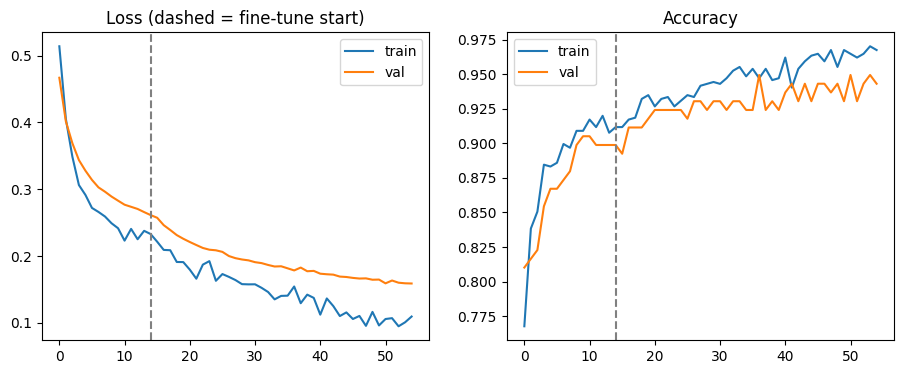

In [ ]:
def cbs():
    return [keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7)]

# ---- Phase 1: head only ----
h1 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=15, batch_size=32, callbacks=cbs())

# ---- Phase 2: fine-tune last 40 backbone layers ----
base.trainable = True
for layer in base.layers[:-40]:
    layer.trainable = False
for layer in base.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
compile_model(model, 2e-5)                      # must recompile after changing trainable flags

h2 = model.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=40, batch_size=32, callbacks=cbs())

hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist["loss"], label="train"); ax[0].plot(hist["val_loss"], label="val")
ax[0].axvline(len(h1.history["loss"]) - 1, ls="--", c="gray"); ax[0].set_title("Loss (dashed = fine-tune start)"); ax[0].legend()
ax[1].plot(hist["accuracy"], label="train"); ax[1].plot(hist["val_accuracy"], label="val")
ax[1].axvline(len(h1.history["loss"]) - 1, ls="--", c="gray"); ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

model.save("/content/drive/MyDrive/model_results/efficientnetb0_scd.keras")

=== EfficientNet-B0 — held-out test set ===
              precision    recall  f1-score   support

      normal      0.957     0.815     0.880        27
      sickle      0.963     0.992     0.977       131

    accuracy                          0.962       158
   macro avg      0.960     0.904     0.929       158
weighted avg      0.962     0.962     0.961       158

ROC-AUC: 0.9731


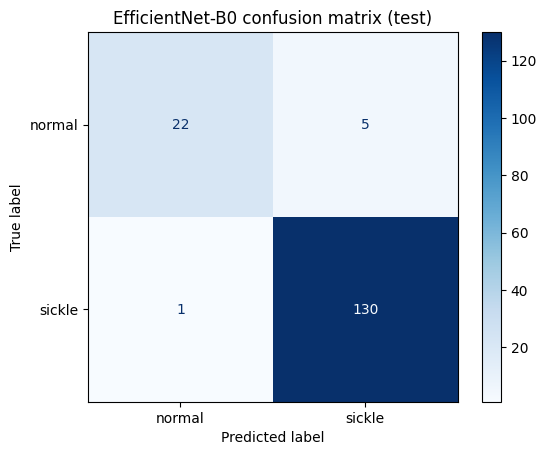

Mean inference time: 323.2 ms/image
{'model': 'EfficientNet-B0', 'params': 4050852, 'accuracy': 0.9620253164556962, 'precision': 0.9629629629629629, 'recall': 0.9923664122137404, 'f1': 0.9774436090225563, 'auc': 0.9731410800113091, 'inference_ms': 323.21896526000046, 'n_test': 158}


In [ ]:
prob = model.predict(Xte, batch_size=32, verbose=0).ravel()
y_true = yte.ravel().astype(int)
y_pred = (prob >= 0.5).astype(int)

print("=== EfficientNet-B0 — held-out test set ===")
print(classification_report(y_true, y_pred, target_names=["normal", "sickle"], digits=3))
auc = roc_auc_score(y_true, prob)
print("ROC-AUC:", round(auc, 4))

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=["normal", "sickle"]).plot(cmap="Blues")
plt.title("EfficientNet-B0 confusion matrix (test)"); plt.show()

# inference time, single image
x1 = Xte[:1].astype("float32")
for _ in range(10): model(x1, training=False)
t0 = time.perf_counter()
for _ in range(100): model(x1, training=False)
ms = (time.perf_counter() - t0) / 100 * 1000
print(f"Mean inference time: {ms:.1f} ms/image")

# save metrics so you can compare models later
results = dict(model="EfficientNet-B0",
               params=int(model.count_params()),
               accuracy=float(accuracy_score(y_true, y_pred)),
               precision=float(precision_score(y_true, y_pred)),
               recall=float(recall_score(y_true, y_pred)),
               f1=float(f1_score(y_true, y_pred)),
               auc=float(auc), inference_ms=float(ms),
               n_test=int(len(y_true)))
json.dump(results, open(RESULTS_DIR / "efficientnetb0.json", "w"), indent=2)
print(results)

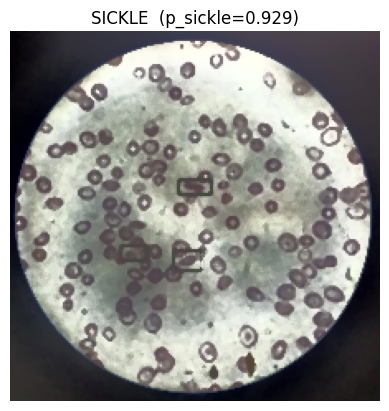

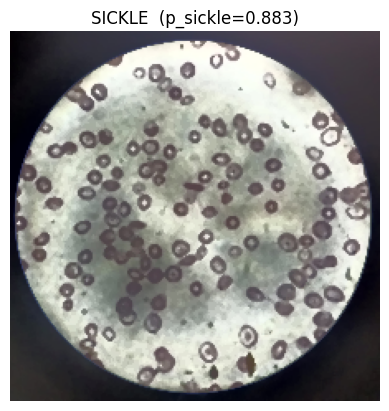

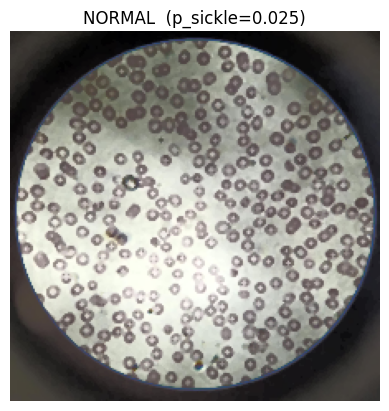

In [ ]:
def predict_image(path):
    img = preprocess(str(path))[None].astype("float32")
    p = float(model.predict(img, verbose=0)[0, 0])
    plt.imshow(img[0].astype("uint8")); plt.axis("off")
    plt.title(f"{'SICKLE' if p >= 0.5 else 'NORMAL'}  (p_sickle={p:.3f})"); plt.show()

predict_image(pos_l[20])
predict_image(pos_u[20])
predict_image(neg[20])